In [6]:
import pandas as pd
import numpy as np
import re
import unicodedata
from pathlib import Path

pd.set_option('display.max_columns', None)

# 1. Chargement des données
BASE_DIR = Path(r"C:\Projet Niger Labor Market\niger_jobs_scraper\data\cleaned")
df_raw = pd.read_csv(BASE_DIR / "offres_nettoyees.csv")



In [7]:
# 2. Filtrage territorial : Niger uniquement
villes_niger = (
    r"(?:niamey|zinder|maradi|agadez|tillab[ée]ri|tahoua|dosso|diffa|niger|"
    r"mirriah|dakoro|t[ée]ra|doutchi|konni|madaoua|goth[èe]ye|tagazar|abalak|"
    r"tchintabaraden|if[ée]rouane|ouallam|filingu[ée]|kollo|say|gaya|magaria|arlit|nguigmi)"
)
mask_niger = (
    df_raw["pays"].fillna("").str.strip().str.lower().eq("niger")
    | df_raw["region"].fillna("").str.contains(villes_niger, case=False, regex=True)
    | df_raw["ville"].fillna("").str.contains(villes_niger, case=False, regex=True)
)
df_niger = df_raw[mask_niger].copy()

# Correction des 2 régions manquantes identifiées à l'audit
df_niger.loc[df_niger["id_offre"] == "OFFRE_171", "region"] = "Tillabéri"
df_niger.loc[df_niger["id_offre"] == "OFFRE_072", "region"] = "National (Tout le Niger)"

df_niger["est_offre_nationale"] = (
    df_niger["region"].fillna("").str.contains(r"national|tout le niger", case=False, regex=True)
    | df_niger["ville"].fillna("").str.contains(r"tout le niger|^niger$", case=False, regex=True)
)


In [8]:
# 3. Segmentation analytique par nature d'annonce
def classer_segment(nat):
    s = str(nat).strip().lower()
    if "appel" in s or "marché" in s:
        return "Marchés & Appels d'offres (B2B)"
    if "formation" in s:
        return "Formations"
    return "Emploi & Consultance"

df_niger["segment_marche"] = df_niger["nature_annonce"].apply(classer_segment)


In [9]:
# 4. Déduplication inter-sites avancée (conservation de la fiche la plus riche)
def norm_text(s):
    if pd.isna(s):
        return ""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode("utf-8").lower()
    s = re.sub(r"[^a-z0-9\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

def norm_employer(emp):
    e = norm_text(emp)
    aliases = {
        "danish refugee council": "drc",
        "conseil danois pour les refugies": "drc",
        "conseil norvegien pour les refugies": "nrc",
        "norwegian refugee council": "nrc",
        "action contre la faim": "acf",
        "programme alimentaire mondial": "pam",
        "complexe scolaire peralta": "peralta",
    }
    for k, v in aliases.items():
        if k in e:
            return v
    return e

STOP_TITRE = {"de", "du", "des", "la", "le", "les", "pour", "en", "et", "a", "au", "aux", "d", "l", "e", "h", "f", "section", "un", "une"}

def token_jaccard(a, b):
    wa = set(norm_text(a).split()) - STOP_TITRE
    wb = set(norm_text(b).split()) - STOP_TITRE
    return len(wa & wb) / len(wa | wb) if (wa | wb) else 0.0

df_niger["score_completude"] = (
    df_niger["niveau_etude"].notnull().astype(int) * 2
    + df_niger["experience_requise"].notnull().astype(int) * 2
    + df_niger["profil_exige_corpus"].notnull().astype(int) * 2
    + df_niger["description_propre"].str.len() / 1000.0
)
df_niger = df_niger.sort_values("score_completude", ascending=False).reset_index(drop=True)

to_drop = set()
merged_sources = df_niger["sources_multiples"].tolist()
merged_urls = df_niger["urls_alternatives"].fillna("").tolist()

for i in range(len(df_niger)):
    if i in to_drop:
        continue
    for j in range(i + 1, len(df_niger)):
        if j in to_drop:
            continue
        r1, r2 = df_niger.iloc[i], df_niger.iloc[j]
        if r1["segment_marche"] != r2["segment_marche"]:
            continue
        diff_site = r1["site_source"] != r2["site_source"]
        same_dl = pd.notna(r1["date_limite_candidature"]) and (r1["date_limite_candidature"] == r2["date_limite_candidature"])
        same_emp = (norm_employer(r1["entreprise_ou_ong"]) == norm_employer(r2["entreprise_ou_ong"])) and norm_employer(r1["entreprise_ou_ong"]) != ""
        j_tit = token_jaccard(r1["titre_poste"], r2["titre_poste"])
        j_desc = token_jaccard(r1["description_propre"], r2["description_propre"])

        if j_desc >= 0.92 or (diff_site and same_emp and same_dl and j_tit >= 0.30):
            to_drop.add(j)
            s_set = {x.strip() for x in f"{merged_sources[i]};{r2['site_source']}".split(";") if x.strip() and x.strip() != "nan"}
            merged_sources[i] = " ; ".join(sorted(s_set))
            u_set = {x.strip() for x in f"{merged_urls[i]};{r2['url_offre']}".split(";") if x.strip() and x.strip() != "nan"}
            merged_urls[i] = " ; ".join(sorted(u_set))

df_niger["sources_multiples"] = merged_sources
df_niger["urls_alternatives"] = [u if u else np.nan for u in merged_urls]
df_clean = df_niger.drop(index=list(to_drop)).sort_values("id_offre").reset_index(drop=True)


In [10]:
# 5. Standardisation des variables analytiques
def std_contrat(row):
    if row["segment_marche"] == "Marchés & Appels d'offres (B2B)":
        return "Appel d'offres / Marché"
    if row["segment_marche"] == "Formations":
        return "Formation"
    tc = str(row["type_contrat"]).lower() if pd.notna(row["type_contrat"]) else ""
    nat = str(row["nature_annonce"]).lower()
    if "indéterminée" in tc or re.search(r"\bcdi\b", tc):
        return "CDI"
    if "déterminée" in tc or re.search(r"\bcdd\b", tc):
        return "CDD"
    if "consult" in tc or "consult" in nat:
        return "Prestation / Consultance"
    if "stage" in tc:
        return "Stage"
    if "bénévolat" in tc or "volontar" in tc:
        return "Bénévolat / Volontariat"
    return "Non précisé / Autre"

def std_niveau(val):
    if pd.isna(val):
        return ("Non précisé", np.nan)
    v = str(val).lower().strip()
    if any(k in v for k in ["doctorat", "phd", "bac+8"]):
        return ("Doctorat (Bac+8)", 5.0)
    if any(k in v for k in ["bac+5", "master", "dess", "ingéniorat", "bac+4/5"]):
        return ("Bac+5 / Master", 4.0)
    if any(k in v for k in ["bac+4", "maîtrise"]):
        return ("Bac+4 / Maîtrise", 3.5)
    if any(k in v for k in ["bac+3", "licence 3", "bachelor", "bepc+3"]):
        return ("Bac+3 / Licence", 3.0)
    if any(k in v for k in ["bac+2", "bts", "licence 2", "dut", "diplôme universitaire"]):
        return ("Bac+2 / BTS / DUT", 2.0)
    if any(k in v for k in ["bepc", "cap", "secondaire", "bac"]):
        return ("Secondaire / BEPC / Bac", 1.0)
    return ("Autre", np.nan)

def parse_exp(val):
    if pd.isna(val):
        return (np.nan, np.nan)
    v = str(val).lower().strip()
    if "débutant" in v or "sans expérience" in v:
        return (0.0, 0.0)
    m_range = re.search(r"(\d+)\s*[-–àa]\s*(\d+)", v)
    if m_range:
        return (float(m_range.group(1)), float(m_range.group(2)))
    m_single = re.search(r"(\d+)", v)
    if m_single:
        num = float(m_single.group(1))
        return (num, np.nan) if ("min" in v or "+" in v or "plus" in v) else (num, num)
    return (np.nan, np.nan)

df_clean["contrat_canonique"] = df_clean.apply(std_contrat, axis=1)
niv = df_clean["niveau_etude"].apply(std_niveau)
df_clean["niveau_etude_std"] = [x[0] for x in niv]
df_clean["niveau_etude_rang"] = [x[1] for x in niv]
exp = df_clean["experience_requise"].apply(parse_exp)
df_clean["exp_min"] = [x[0] for x in exp]
df_clean["exp_max"] = [x[1] for x in exp]
df_clean["salaire_explicite"] = df_clean["salaire_affiche"].notna() & (
    ~df_clean["salaire_affiche"].astype(str).str.lower().str.contains("non communiqu|na|none")
)


In [11]:
# 6. Sauvegarde des jeux de données propres
df_emploi = df_clean[df_clean["segment_marche"] == "Emploi & Consultance"].reset_index(drop=True)
df_clean.to_csv(BASE_DIR / "offres_niger_uniques.csv", index=False)
df_emploi.to_csv(BASE_DIR / "offres_niger_emploi.csv", index=False)

print(f"Sauvegarde réussie : {len(df_clean)} annonces uniques Niger | {len(df_emploi)} offres Emploi & Consultance.")

Sauvegarde réussie : 145 annonces uniques Niger | 70 offres Emploi & Consultance.


# Analyses Descriptives Univariées et Bivariées

In [12]:
import pandas as pd
import numpy as np
import re
import unicodedata
from pathlib import Path
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.dpi"] = 140
sns.set_theme(style="whitegrid", palette="Set2")

BASE_DIR = Path(r"C:\Projet Niger Labor Market\niger_jobs_scraper\data\cleaned")
df_clean = pd.read_csv(BASE_DIR / "offres_niger_uniques.csv")

def norm_text(s):
    if pd.isna(s):
        return ""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode("utf-8").lower()
    s = re.sub(r"[^a-z0-9\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()


In [13]:
# ==============================================================================
# 1. VARIABLES TEMPORELLES & DUREE D'AFFICHAGE
# ==============================================================================
df_clean["dt_pub"] = pd.to_datetime(df_clean["date_publication"], errors="coerce")
df_clean["dt_lim"] = pd.to_datetime(df_clean["date_limite_candidature"], errors="coerce")
df_clean["duree_affichage_j"] = (df_clean["dt_lim"] - df_clean["dt_pub"]).dt.days
df_clean["mois_pub"] = df_clean["dt_pub"].dt.to_period("M").astype(str)
df_clean["semaine_pub"] = df_clean["dt_pub"].dt.to_period("W-MON").apply(lambda r: r.start_time.strftime("%Y-%m-%d"))

jours_fr = {
    0: "1. Lundi", 1: "2. Mardi", 2: "3. Mercredi",
    3: "4. Jeudi", 4: "5. Vendredi", 5: "6. Samedi", 6: "7. Dimanche"
}
df_clean["jour_semaine_pub"] = df_clean["dt_pub"].dt.dayofweek.map(jours_fr)


In [14]:
# ==============================================================================
# 2. TYPOLOGIE DES EMPLOYEURS & MACRO-SECTEURS CANONIQUES
# ==============================================================================
def classer_employeur(row):
    emp = norm_text(row["entreprise_ou_ong"])
    desc = norm_text(str(row["description_propre"])[:600])
    if any(k in emp for k in ["pnud", "programme alimentaire mondial", "pam", "fao", "unicef", "oms", "hcr", "unfpa", "croix rouge", "red crescent", "croissant rouge"]):
        return "Agences ONU & Croix-Rouge"
    if any(k in emp for k in ["programme national", "ministere", "agence nationale", "pnlp", "projet d appui", "pacipa"]):
        return "Programmes Publics & Projets d'État"
    ong_kw = [
        "ong", "rescue", "nrc", "norvegien", "drc", "danois", "action contre la faim", "acf",
        "medecins du monde", "world vision", "psi", "population services", "memisa", "path",
        "swisscontact", "swissaid", "plan international", "islamic relief", "pathfinder",
        "asb", "arbeiter", "corus", "humanite et inclusion", "action education", "sahara conservation",
        "eam progres", "reped", "adkoul", "antd", "solidarite", "atpf", "helen keller", "cesao", "davycas"
    ]
    if any(k in emp for k in ong_kw) or "ong nationale" in desc or "organisation non gouvernementale" in desc:
        return "ONG (Internationales & Nationales)"
    return "Secteur Privé & Cabinets"

def std_secteur(sec):
    if pd.isna(sec):
        return "Non précisé"
    s = norm_text(sec)
    if any(k in s for k in ["sante", "medecine", "pharmacie"]):
        return "Santé & Action médicale"
    if any(k in s for k in ["eau", "hygiene", "assainissement", "wash"]):
        return "Eau, Hygiène & Assainissement (WASH)"
    if any(k in s for k in ["humanitaire", "ong", "social", "associatif"]):
        return "Humanitaire, Projets & Social"
    if any(k in s for k in ["comptabilite", "finance", "banque", "assurance", "economie"]):
        return "Finance, Banque & Comptabilité"
    if any(k in s for k in ["agriculture", "elevage", "rural", "environnement", "durable"]):
        return "Agriculture, Élevage & Environnement"
    if any(k in s for k in ["education", "formation", "recherche", "coaching"]):
        return "Éducation, Formation & Recherche"
    if any(k in s for k in ["logistique", "transport", "supply", "achats"]):
        return "Logistique, Transport & Supply Chain"
    if any(k in s for k in ["btp", "immobilier", "genie civil", "industrie", "mecanique", "maintenance", "energie", "mines", "petrole"]):
        return "BTP, Industrie, Mines & Énergie"
    if any(k in s for k in ["informatique", "tech", "tic", "telecom"]):
        return "Informatique, Télécoms & Digital"
    if any(k in s for k in ["administration", "gestion", "direction", "ressources humaines", "juridique", "statistiques", "suivi", "prestation", "services"]):
        return "Administration, Conseil & Services"
    if any(k in s for k in ["marketing", "vente", "commerce", "hotellerie", "restauration", "tourisme", "alimentation", "securite"]):
        return "Commerce, Marketing & Services marchands"
    return "Autre"

df_clean["type_employeur"] = df_clean.apply(classer_employeur, axis=1)
df_clean["secteur_canonique"] = df_clean["secteur_activite"].apply(std_secteur)

# Indicateur élargi de transparence salariale / barémique (ODD 8)
pat_comp = (
    r"(?:grille\s+salariale|grade\s*[:\-]?\s*[a-z0-9]+|rémunération\s+(?:attractive|compétitive|selon)|"
    r"salaire\s+(?:brut|net|mensuel|selon|compétitif|attractif)|avantages\s+sociaux|"
    r"assurance\s+(?:maladie|santé)|13[èe]me\s+mois|indemnité|per\s*diem|honoraires)"
)
df_clean["mention_grille_avantages"] = df_clean["description_propre"].str.contains(pat_comp, case=False, regex=True, na=False)

def niveau_transparence_sal(row):
    if pd.notna(row["salaire_affiche"]) and "non communiqu" not in str(row["salaire_affiche"]).lower():
        return "1. Montant explicite affiché"
    if row["mention_grille_avantages"]:
        return "2. Grille / Grade / Avantages mentionnés"
    return "3. Opacité salariale totale"

df_clean["transparence_salariale"] = df_clean.apply(niveau_transparence_sal, axis=1)

# Isolement du cœur d'analyse Emploi & Consultance (n=70)
emp = df_clean[df_clean["segment_marche"] == "Emploi & Consultance"].reset_index(drop=True)


In [16]:
# ==============================================================================
# 3. TABLEAUX STATISTIQUES DESCRIPTIFS & BIVARIES
# ==============================================================================
print("=== 1. DYNAMIQUE TEMPORELLE (EMPLOI & CONSULTANCE n=70) ===")
print("\nPar semaine (lundi de début) :")
print(emp["semaine_pub"].value_counts().sort_index())

print("\nPar jour de la semaine :")
print(pd.DataFrame({
    "Emploi_n": emp["jour_semaine_pub"].value_counts(),
    "Emploi_%": (emp["jour_semaine_pub"].value_counts(normalize=True) * 100).round(1),
    "Total_Niger_n": df_clean["jour_semaine_pub"].value_counts(),
    "Total_Niger_%": (df_clean["jour_semaine_pub"].value_counts(normalize=True) * 100).round(1),
}).sort_index())

print("\n=== 2. DUREE D'AFFICHAGE PAR EMPLOYEUR ===")
print(emp.groupby("type_employeur")["duree_affichage_j"].agg(["count", "mean", "median", "std", "min", "max"]).round(2))
dur_ong_onu = emp[emp["type_employeur"].isin(["ONG (Internationales & Nationales)", "Agences ONU & Croix-Rouge"])]["duree_affichage_j"]
dur_prive = emp[emp["type_employeur"] == "Secteur Privé & Cabinets"]["duree_affichage_j"]
u_stat, p_dur = stats.mannwhitneyu(dur_ong_onu, dur_prive, alternative="two-sided")
print(f"Test Mann-Whitney (ONG/ONU vs Privé) : U = {u_stat:.1f}, p = {p_dur:.4f}")

print("\n=== 3. STRUCTURE SECTORIELLE & EMPLOYEURS ===")
print(pd.DataFrame({
    "Effectif": emp["secteur_canonique"].value_counts(),
    "Part_%": (emp["secteur_canonique"].value_counts(normalize=True) * 100).round(1)
}))

print("\n=== 4. CROISEMENTS BIVARIES ===")
print("\n4A. Niveau d'études vs Expérience minimale requise :")
print(emp.groupby("niveau_etude_std")["exp_min"].agg(["count", "mean", "median", "std", "min", "max"]).round(2))
sub_corr = emp[["niveau_etude_rang", "exp_min"]].dropna()
rho, p_rho = stats.spearmanr(sub_corr["niveau_etude_rang"], sub_corr["exp_min"])
print(f"Corrélation de Spearman : rho = {rho:.3f}, p = {p_rho:.4f} (n={len(sub_corr)})")

print("\n4B. Transparence salariale / barémique selon l'employeur (%) :")
print((pd.crosstab(emp["type_employeur"], emp["transparence_salariale"], normalize="index") * 100).round(1))


=== 1. DYNAMIQUE TEMPORELLE (EMPLOI & CONSULTANCE n=70) ===

Par semaine (lundi de début) :
semaine_pub
2026-10-06     3
2026-10-20     9
2026-10-27    18
2026-11-03    16
2026-11-10     9
2026-11-17    15
Name: count, dtype: int64

Par jour de la semaine :
                  Emploi_n  Emploi_%  Total_Niger_n  Total_Niger_%
jour_semaine_pub                                                  
1. Lundi              14.0      20.0             36           24.8
2. Mardi              10.0      14.3             31           21.4
3. Mercredi           22.0      31.4             28           19.3
4. Jeudi               9.0      12.9             22           15.2
5. Vendredi           15.0      21.4             25           17.2
6. Samedi              NaN       NaN              2            1.4
7. Dimanche            NaN       NaN              1            0.7

=== 2. DUREE D'AFFICHAGE PAR EMPLOYEUR ===
                                     count   mean  median   std  min  max
type_employeur       

C:\Users\AbdoulLocal\AppData\Local\Temp\ipykernel_22504\470178039.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=emp, x="type_employeur", y="duree_affichage_j", order=order_emp, ax=ax3, palette="Set2", width=0.45, showfliers=False)
C:\Users\AbdoulLocal\AppData\Local\Temp\ipykernel_22504\470178039.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax3.set_xticklabels(labels_emp, fontsize=9)
C:\Users\AbdoulLocal\AppData\Local\Temp\ipykernel_22504\470178039.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub_box, x="niveau_etude_std", y="exp_min", orde

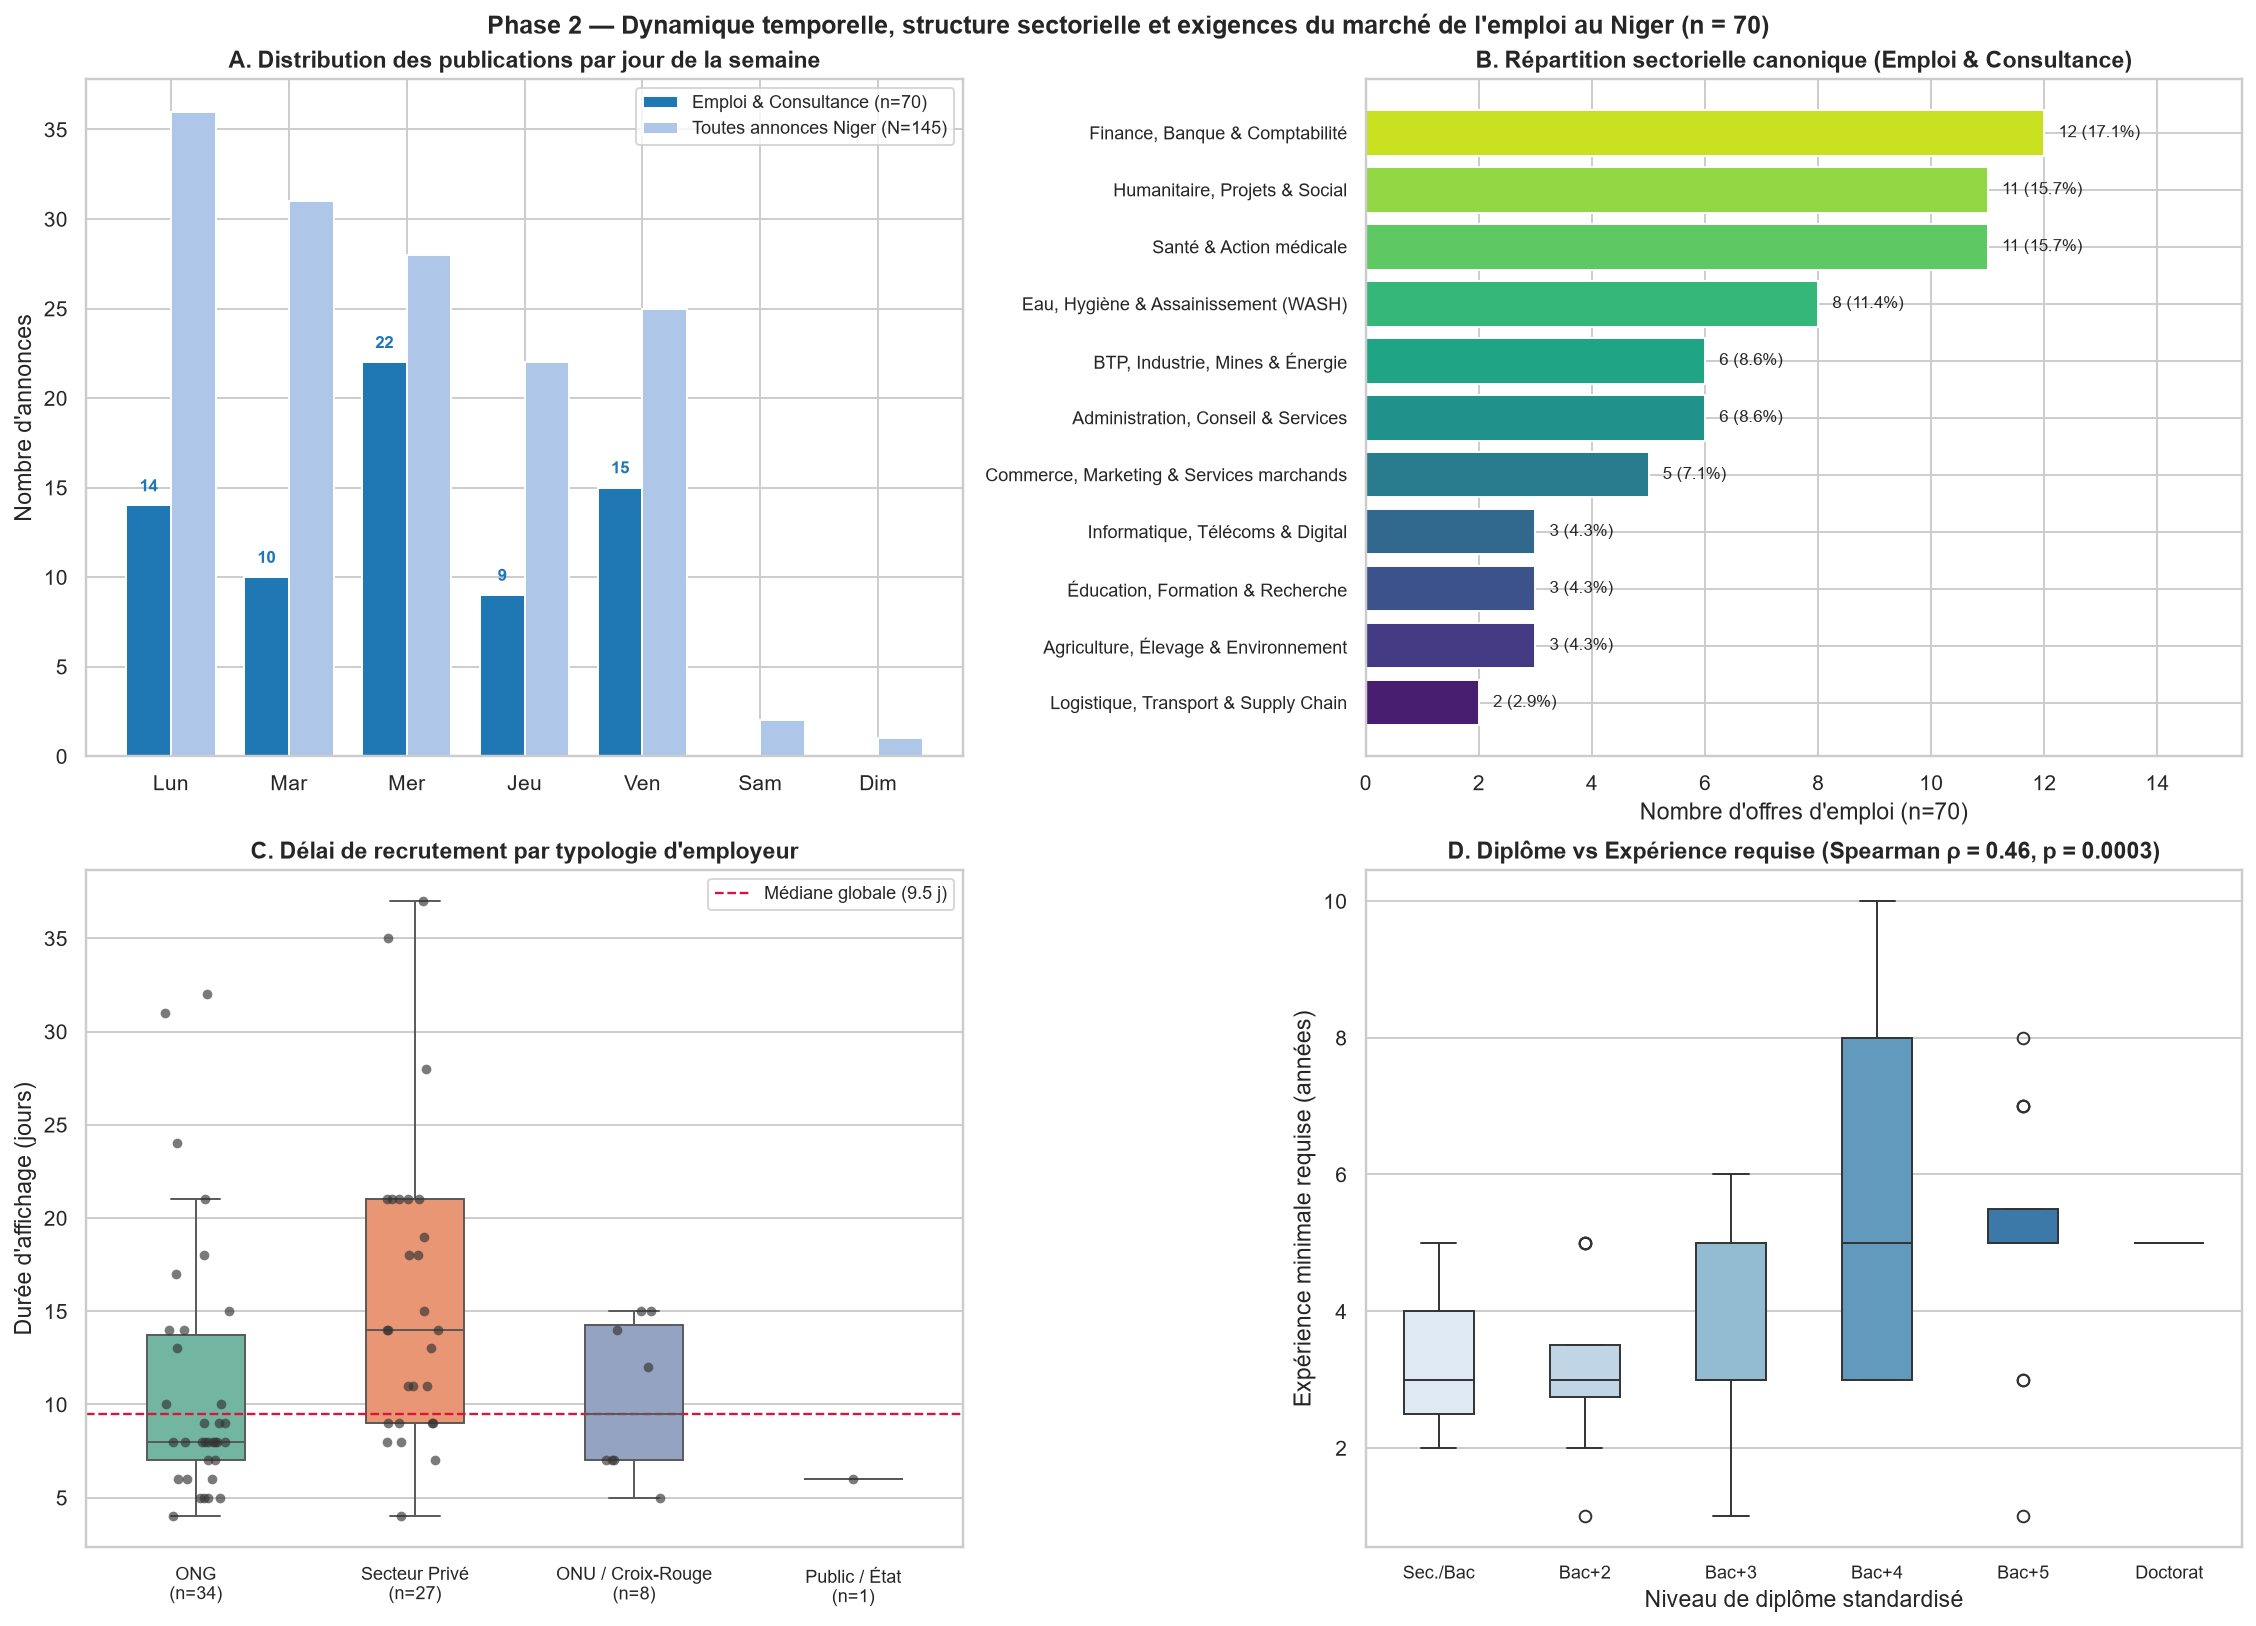

In [17]:
# ==============================================================================
# 4. VISUALISATION SYNTHETIQUE 2x2
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 11.5), constrained_layout=True)

# A. Saisonnalité infra-hebdomadaire
ax1 = axes[0, 0]
jours_ordre = ["1. Lundi", "2. Mardi", "3. Mercredi", "4. Jeudi", "5. Vendredi", "6. Samedi", "7. Dimanche"]
jours_labels = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
c_emp = emp["jour_semaine_pub"].value_counts().reindex(jours_ordre, fill_value=0)
c_tot = df_clean["jour_semaine_pub"].value_counts().reindex(jours_ordre, fill_value=0)
x = np.arange(len(jours_ordre))
w = 0.38
ax1.bar(x - w/2, c_emp.values, width=w, label="Emploi & Consultance (n=70)", color="#1f77b4")
ax1.bar(x + w/2, c_tot.values, width=w, label="Toutes annonces Niger (N=145)", color="#aec7e8")
ax1.set_xticks(x)
ax1.set_xticklabels(jours_labels)
ax1.set_ylabel("Nombre d'annonces")
ax1.set_title("A. Distribution des publications par jour de la semaine", fontweight="bold")
ax1.legend(frameon=True, fontsize=9)
for i, v in enumerate(c_emp.values):
    if v > 0:
        ax1.text(i - w/2, v + 0.6, str(v), ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#1f77b4")

# B. Macro-secteurs canoniques
ax2 = axes[0, 1]
sec_counts = emp["secteur_canonique"].value_counts().sort_values(ascending=True)
ax2.barh(sec_counts.index, sec_counts.values, color=sns.color_palette("viridis", len(sec_counts)))
ax2.set_xlabel("Nombre d'offres d'emploi (n=70)")
ax2.set_title("B. Répartition sectorielle canonique (Emploi & Consultance)", fontweight="bold")
ax2.tick_params(axis="y", labelsize=9)
for i, v in enumerate(sec_counts.values):
    ax2.text(v + 0.25, i, f"{v} ({v/len(emp)*100:.1f}%)", va="center", fontsize=8.5)
ax2.set_xlim(0, sec_counts.max() + 3.5)

# C. Délai de recrutement par typologie d'employeur
ax3 = axes[1, 0]
order_emp = ["ONG (Internationales & Nationales)", "Secteur Privé & Cabinets", "Agences ONU & Croix-Rouge", "Programmes Publics & Projets d'État"]
labels_emp = ["ONG\n(n=34)", "Secteur Privé\n(n=27)", "ONU / Croix-Rouge\n(n=8)", "Public / État\n(n=1)"]
sns.boxplot(data=emp, x="type_employeur", y="duree_affichage_j", order=order_emp, ax=ax3, palette="Set2", width=0.45, showfliers=False)
sns.stripplot(data=emp, x="type_employeur", y="duree_affichage_j", order=order_emp, ax=ax3, color="#333333", alpha=0.65, jitter=0.15, size=5)
ax3.axhline(emp["duree_affichage_j"].median(), color="crimson", linestyle="--", linewidth=1.2, label=f"Médiane globale ({emp['duree_affichage_j'].median():.1f} j)")
ax3.set_xticklabels(labels_emp, fontsize=9)
ax3.set_xlabel("")
ax3.set_ylabel("Durée d'affichage (jours)")
ax3.set_title("C. Délai de recrutement par typologie d'employeur", fontweight="bold")
ax3.legend(fontsize=9)

# D. Niveau d'études vs Expérience minimale requise
ax4 = axes[1, 1]
order_niv = ["Secondaire / BEPC / Bac", "Bac+2 / BTS / DUT", "Bac+3 / Licence", "Bac+4 / Maîtrise", "Bac+5 / Master", "Doctorat (Bac+8)"]
labels_niv = ["Sec./Bac", "Bac+2", "Bac+3", "Bac+4", "Bac+5", "Doctorat"]
sub_box = emp[emp["niveau_etude_std"].isin(order_niv) & emp["exp_min"].notna()]
sns.boxplot(data=sub_box, x="niveau_etude_std", y="exp_min", order=order_niv, ax=ax4, palette="Blues", width=0.48)
ax4.set_xticklabels(labels_niv, fontsize=9)
ax4.set_xlabel("Niveau de diplôme standardisé")
ax4.set_ylabel("Expérience minimale requise (années)")
ax4.set_title(f"D. Diplôme vs Expérience requise (Spearman ρ = {rho:.2f}, p = {p_rho:.4f})", fontweight="bold")

fig.suptitle("Phase 2 — Dynamique temporelle, structure sectorielle et exigences du marché de l'emploi au Niger (n = 70)", fontsize=13, fontweight="bold")
plt.savefig(BASE_DIR / "phase2_analyse_descriptive.png", bbox_inches="tight")
plt.show()



In [18]:
# ==============================================================================
# 5. SAUVEGARDE DES TABLES ENRICHIES POUR LES NOTEBOOKS 02 & 03
# ==============================================================================
df_clean.to_csv(BASE_DIR / "offres_niger_uniques.csv", index=False)
emp.to_csv(BASE_DIR / "offres_niger_emploi.csv", index=False)
print("\nFichiers enrichis sauvegardés avec succès pour la Phase 3 (02_extraction_regles_nlp.ipynb).")


Fichiers enrichis sauvegardés avec succès pour la Phase 3 (02_extraction_regles_nlp.ipynb).
